## Seminário 2
Dataset: [Student Stress Factors: A Comprehensive Analysis](https://www.kaggle.com/datasets/rxnach/student-stress-factors-a-comprehensive-analysis)

Sobre a base de dados escolhida:
- São dados sintéticos que buscam simular fatores associados ao estresse acadêmico em uma amostra de 1100 indivíduos.
- O foco é a análise estatística em vez de tratamento dos dados (algo que foi necessário na base selecionada para o Seminário 1).
- Embora o conjunto de dados original disponha de cerca de vinte variáveis, selecionou-se um subconjunto composto por "anxiety_level", "self_esteem", "sleep_quality", "academic_performance" e "study_load". Essa delimitação fundamentou-se no objetivo de analisar a interação entre fatores psicológicos (2), acadêmicos (2) e fisiológicos (1) que apresentam forte correlação entre si.

In [50]:
import pandas as pd

In [51]:
# N° de variáveis limitado a 5, conforme estipulado na diretriz do trabalho
cols = ["anxiety_level", "self_esteem", "sleep_quality", "academic_performance", "study_load"]
df = pd.read_csv("StressLevelDataset.csv", usecols=cols)
df.head()

,anxiety_level,self_esteem,sleep_quality,academic_performance,study_load
0,14,20,2,3,2
1,15,8,1,1,4
2,12,18,2,2,3
3,16,12,1,2,4
4,16,28,5,4,3


In [52]:
# Medidas descritivas das variáveis do dataset
df.describe()

,anxiety_level,self_esteem,sleep_quality,academic_performance,study_load
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,2.660000,2.772727,2.621818
std,6.117558,8.944599,1.548383,1.414594,1.315781
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,1.000000,2.000000,2.000000
50%,11.000000,19.000000,2.500000,2.000000,2.000000
75%,16.000000,26.000000,4.000000,4.000000,3.000000
max,21.000000,30.000000,5.000000,5.000000,5.000000


In [53]:
matriz_correlacao = df.corr()
matriz_correlacao

,anxiety_level,self_esteem,sleep_quality,academic_performance,study_load
anxiety_level,1.000000,-0.672745,-0.710292,-0.649601,0.586064
self_esteem,-0.672745,1.000000,0.662693,0.639045,-0.575112
sleep_quality,-0.710292,0.662693,1.000000,0.671326,-0.551775
academic_performance,-0.649601,0.639045,0.671326,1.000000,-0.520417
study_load,0.586064,-0.575112,-0.551775,-0.520417,1.000000


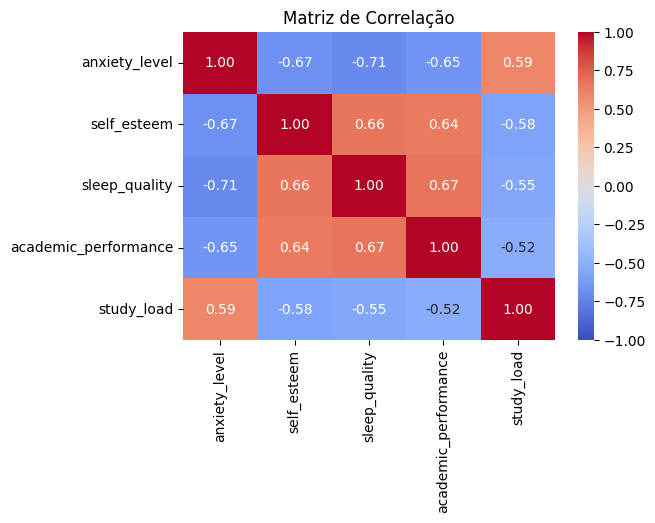

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Matriz de Correlação')
plt.show()

## PCA
A PCA implementada na biblioteca statsmodels tem a padronização dos dados como comportamento default. 

A PCA busca direções que maximizam a variância dos dados. Como a variância depende diretamente da unidade de medida (escala), qualquer variável com números maiores vai "dominar" os componentes principais de forma artificial, de modo que a padronização é necessária.  

In [55]:
import numpy as np
from statsmodels.multivariate.pca import PCA
# PCA padrão (padroniza os dados: média 0 e variância 1, equivalente à matriz de correlação)
# method='eig' é um parâmetro adicional que calcula os autovalores exatos da matriz de correlação
model = PCA(df, ncomp=5, method='eig')

In [56]:
print(model.loadings)

                        comp_0    comp_1    comp_2    comp_3    comp_4
anxiety_level        -0.464405  0.094399 -0.327777 -0.441272 -0.687938
self_esteem           0.454597 -0.057157  0.493546 -0.735082 -0.078371
sleep_quality         0.461643 -0.264211  0.119328  0.460824 -0.700343
academic_performance  0.445344 -0.376090 -0.764721 -0.225502  0.156762
study_load           -0.407706 -0.881232  0.223466 -0.041517  0.074464


In [ ]:
n = df.shape[0]
autovalores = model.eigenvals.to_numpy() / n
proporcao = autovalores / autovalores.sum()
acumulada = np.cumsum(proporcao)
componentes = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']

# Tabela de Autovalores e Variância
tabela_autovalores = pd.DataFrame(
    [autovalores, proporcao, acumulada],
    index=['Autovalor', 'Proporção', 'Acumulada'],
    columns=componentes,
)

print(tabela_autovalores) # O primeiro componente explica 70% da variabilidade dos dados

                PC1       PC2       PC3       PC4       PC5
Autovalor  3.502054  0.512382  0.356451  0.344264  0.284848
Proporção  0.700411  0.102476  0.071290  0.068853  0.056970
Acumulada  0.700411  0.802887  0.874178  0.943030  1.000000


### Interpretação dos componentes
- comp_0: Índice Geral de Bem-Estar e Adaptação Acadêmica

    Explica a maior parte da variância dos dados. Apresenta pesos parecidos em magnitude, mas com sinais opostos: no polo positivo, estão variáveis de bem-estar e rendimento, enquanto que no polo negativo estão variáveis de pressão psicológica e acadêmica. Isso indica que, para a grande maioria dos estudantes, os indicadores caminharam em bloco: maior qualidade de sono, autoestima e desempenho acadêmico estão fortemente associados a menores níveis de ansiedade e menor sensação de sobrecarga nos estudos.

- comp_1: Pressão e Volume de Estudos


    É o segundo maior componente, elevando a variância acumulada para 80,29%. É fortemente dominado por study_load (-0,881), acompanhado em menor grau por academic_performance (-0,376) e sleep_quality (-0,264), todos no mesmo sentido. 
    
    Ele captura a variação ligada diretamente ao volume de estudos que não foi absorvida pelo eixo geral de bem-estar, e mostra que existe uma parcela da variabilidade em que a carga de estudo varia acompanhada de algum reflexo no desempenho acadêmico e no sono, independentemente da ansiedade (0,094) ou da autoestima (-0,057). São estudantes que enfrentam uma alta carga de estudos, mas conseguem manter bom desempenho e bom sono sem que a ansiedade (0,094) dispare. 

- comp_2: Contraste entre Desempenho Acadêmico e Autoestima

    A partir deste ponto, os autovalores estabilizam em um patamar próximo (entre 313 e 392), representando dimensões mais sutis e específicas de subgrupos da amostra.

    Esse componente retrata perfis em que o rendimento acadêmico e a autopercepção caminham em direções opostas. Por exemplo, estudantes que alcançam bom desempenho acadêmico sob certa ansiedade, mas mantêm baixa autoestima (traços de autocrítica ou perfeccionismo), ou o inverso.

- comp_3: Dissociação entre Autoestima e Qualidade do Sono

    Explica praticamente a mesma proporção de variância que o comp_2, atuando como ajuste fino da estrutura latente. Concentra-se na oposição entre self_esteem (-0,735) e sleep_quality (0,461), com anxiety_level (-0,441) acompanhando o polo de self_esteem. Isola variações residuais específicas em que a qualidade do sono não se traduz em melhora na autoestima (ou em que estudantes com boa autoestima relatam pior qualidade de sono).

- comp_4: Eixo Residual de Sono e Ansiedade

    É o componente de menor peso explicativo (5,70%), responsável por completar os 100% da variância total do sistema. Apresenta cargas altas e de mesmo sinal em sleep_quality (-0,700) e anxiety_level (-0,688), com participação quase nula das demais variáveis.

    Embora exiba cargas numericamente elevadas, seu baixo autovalor indica tratar-se de uma dimensão residual, capturando casos pontuais em que sono e ansiedade variam na mesma direção (por exemplo, aumento simultâneo de ansiedade e sono), contrariando a relação inversa dominante observada no comp_0.

### Antes de aplicar análise fatorial...
Para verificar a adequação da base de dados à Análise Fatorial, foram aplicados o índice de **Kaiser-Meyer-Olkin (KMO)** e o **teste de esfericidade de Bartlett**. 

* **Índice KMO:** O valor geral obtido foi de **0,885** (classificado como *bom* segundo os critérios de Kaiser), demonstrando que a amostra possui alta proporção de variância comum entre as variáveis.
* **Teste de Esfericidade de Bartlett:** Apresentou $\chi^2(10) = 3036,25$ com $p < 0,001$, rejeitando a hipótese nula de que a matriz de correlação seja uma matriz identidade.

Esses resultados confirmam a existência de correlações estatisticamente significativas e atestam a viabilidade técnica para a extração dos fatores latentes.

In [10]:
import numpy as np
from scipy.stats import chi2

n, p = df.shape

# Matriz de correlação (R) e sua inversa (R_inv)
R = np.corrcoef(df, rowvar=False)
R_inv = np.linalg.inv(R)

# --- 1. Teste de Bartlett ---
det_R = np.linalg.det(R)
chi2_stat = - (n - 1 - (2 * p + 5) / 6) * np.log(det_R)
gl = p * (p - 1) / 2
p_valor = chi2.sf(chi2_stat, gl)

print(f'Bartlett Qui-quadrado: {chi2_stat:.4f} (gl={int(gl)}), p-valor: {p_valor:.4e}')

# --- 2. KMO ---
# Matriz de correlações parciais anti-imagem
D = np.diag(1 / np.sqrt(np.diag(R_inv)))
Q = - D @ R_inv @ D
np.fill_diagonal(Q, 0)

R_sem_diag = R.copy()
np.fill_diagonal(R_sem_diag, 0)

kmo_geral = np.sum(R_sem_diag**2) / (np.sum(R_sem_diag**2) + np.sum(Q**2))
kmo_variaveis = np.sum(R_sem_diag**2, axis=0) / (np.sum(R_sem_diag**2, axis=0) + np.sum(Q**2, axis=0))

print(f'KMO Geral: {kmo_geral:.4f}')
for col, val in zip(cols, kmo_variaveis):
    print(f'  KMO {col}: {val:.4f}')


Bartlett Qui-quadrado: 3036.2498 (gl=10), p-valor: 0.0000e+00
KMO Geral: 0.8851
  KMO anxiety_level: 0.8689
  KMO self_esteem: 0.8884
  KMO sleep_quality: 0.8673
  KMO academic_performance: 0.8929
  KMO study_load: 0.9199


## Análise Fatorial

In [11]:
from statsmodels.multivariate.factor import Factor

# Ajuste do modelo de Análise Fatorial com 2 fatores
fa = Factor(df, n_factor=2, method='pa')
res = fa.fit()

# Primeira impressão dos factor loadings
# O segundo fator sem rotação é praticamente ruído (não representa nenhuma variável porque os valores são baixíssimos)
res.loadings

array([[ 0.83709043, -0.00456535],
       [-0.80707129, -0.04560828],
       [-0.83892488,  0.14734322],
       [-0.78383733,  0.10108133],
       [ 0.69900005,  0.24299524]])

In [12]:
# Aplicação da rotação Varimax para redistribuir a variância e permitir interpretar a dimensão secundária no plano bidimensional
res.rotate('varimax')
res.loadings

array([[ 0.69573464,  0.4655046 ],
       [-0.64274843, -0.49022306],
       [-0.77729706, -0.34830196],
       [-0.70574525, -0.35572748],
       [ 0.44259912,  0.59308833]])

In [13]:
# --- SAÍDA 1: Cargas Fatoriais, Comunalidades e Coeficientes dos escores fatoriais ---
coef_escores = res.factor_score_params(method='regression')
tabela_fatorial = pd.DataFrame({
    'Fator 1 (Carga)': res.loadings[:, 0],
    'Fator 2 (Carga)': res.loadings[:, 1],
    'Comunalidade (h²)': res.communality,
    'Coef. Escore F1': coef_escores[:, 0],
    'Coef. Escore F2': coef_escores[:, 1]
}, index=cols)

print("=== CARGAS FATORIAIS, COMUNALIDADES E COEFICIENTES DOS ESCORES ===")
print(tabela_fatorial.round(4))

=== CARGAS FATORIAIS, COMUNALIDADES E COEFICIENTES DOS ESCORES ===
                      Fator 1 (Carga)  Fator 2 (Carga)  Comunalidade (h²)  \
anxiety_level                  0.6957           0.4655             0.7007   
self_esteem                   -0.6427          -0.4902             0.6534   
sleep_quality                 -0.7773          -0.3483             0.7255   
academic_performance          -0.7057          -0.3557             0.6246   
study_load                     0.4426           0.5931             0.5476   

                      Coef. Escore F1  Coef. Escore F2  
anxiety_level                  0.2017           0.1756  
self_esteem                   -0.1099          -0.2416  
sleep_quality                 -0.4520           0.1622  
academic_performance          -0.2673           0.0455  
study_load                    -0.1274           0.4644  


**Fator 1 - Saúde Mental e Baixo Rendimento**
- Polo positivo: anxiety_level (0,6957) e, em menor grau, study_load (0,4426).
- Polo negativo: sleep_quality (-0,7773), academic_performance (-0,7057) e self_esteem (-0,6427).
- Interpretação: Representa o eixo de desgaste emocional e fisiológico. Estudantes com escores altos no Fator 1 apresentam pior qualidade de sono, menor desempenho acadêmico e menor autoestima, associados a níveis elevados de ansiedade.

**Fator 2 - Sobrecarga Acadêmica**
- Polo positivo: study_load (0,5931) e anxiety_level (0,4655).
- Polo negativo: self_esteem (-0,4902), academic_performance (-0,3557) e sleep_quality (-0,3483).
- Interpretação: é dominado pela carga de estudos (study_load), acompanhada de ansiedade e queda na autoestima. Repare que, ao contrário da PCA sem rotação, aqui study_load mantém o sinal oposto ao desempenho acadêmico (-0,3557) e ao sono (-0,3483), confirmando que a sobrecarga de estudos está associada a prejuízos na autoestima, no sono e no desempenho (considerando a estrutura fatorial rotacionada).

As **comunalidades** indicam a proporção da variância de cada variável explicada em conjunto pelos dois fatores. sleep_quality (72,55%) e anxiety_level (70,07%) são as variáveis mais bem capturadas pelos dois fatores. As variáveis restantes têm mais da metade de sua variância explicada, mostrando que o modelo de 2 fatores retém uma boa parcela da informação original.

In [14]:
# --- SAÍDA 2: Variância Explicada por Fator ---
# Na matriz rotacionada, a variância explicada por fator é a soma dos quadrados das cargas
var_explicada = np.sum(res.loadings**2, axis=0)
prop_variancia = var_explicada / len(cols)
prop_acumulada = np.cumsum(prop_variancia)

tabela_variancia = pd.DataFrame({
    'Variância Explicada (SS Loadings)': var_explicada,
    'Proporção da Variância (%)': prop_variancia * 100,
    'Variância Acumulada (%)': prop_acumulada * 100
}, index=['Fator 1 (F1)', 'Fator 2 (F2)'])

print("\n=== VARIÂNCIA EXPLICADA POR FATOR ===")
print(tabela_variancia.round(2))


=== VARIÂNCIA EXPLICADA POR FATOR ===
              Variância Explicada (SS Loadings)  Proporção da Variância (%)  \
Fator 1 (F1)                               2.20                       43.91   
Fator 2 (F2)                               1.06                       21.13   

              Variância Acumulada (%)  
Fator 1 (F1)                    43.91  
Fator 2 (F2)                    65.04  


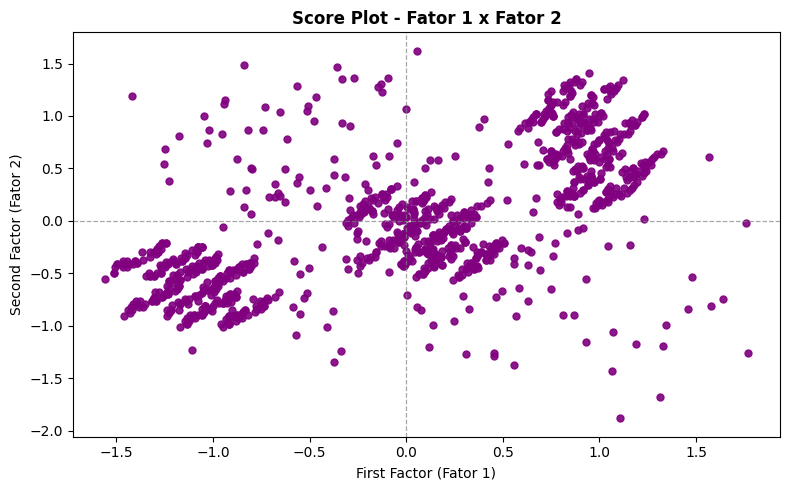

In [15]:
# --- GRÁFICO: Score Plot (gráfico de dispersão das observações/indivíduos nos eixos dos dois fatores) ---

# Calcula os escores fatoriais (já considerando a rotação Varimax aplicada antes)
scores = res.factor_scoring(method='regression') 

# Plota o gráfico de dispersão (Score Plot)
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(scores[:, 0], scores[:, 1], color='purple', s=25, alpha=0.9)

# Linhas pontilhadas cruzando no zero (igual ao slide)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.9, alpha=0.7)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.9, alpha=0.7)

# Títulos e eixos
ax.set_title('Score Plot - Fator 1 x Fator 2', fontsize=12, fontweight='bold')
ax.set_xlabel('First Factor (Fator 1)', fontsize=10)
ax.set_ylabel('Second Factor (Fator 2)', fontsize=10)

plt.tight_layout()
plt.show()